# Hindenburg Omen on China A-Shares: Full Walkthrough

[中文版](walkthrough_zh.ipynb)

This notebook walks through the whole study from start to finish. Every calculation calls the project's
`.py` modules; no logic is re-implemented here.

1. The indicator
2. Load data and compute market breadth
3. The four conditions and the signal
4. Group signals into clusters and measure subsequent drawdowns
5. **Hit rate vs. base rate** (the key result)
6. Case study: why there was no signal in 2015
7. Summary across five indices
8. Conclusions and limitations

> For routine data updates and building the dashboard, use the command line (`python hindenburg.py ...`); see the README.

## 0. Setup

Data is read from `data/` by default. If yours lives elsewhere, set `HO_DATA_DIR` **before** importing the
project modules. `HO_OFFLINE=1` means local data only, no connection to JoinQuant.

The project's modules print progress messages in Chinese; `quiet()` below hides them to keep this notebook's
output clean.

In [1]:
import os
# os.environ['HO_DATA_DIR'] = '/path/to/your/data'   # uncomment if your data is not in data/
os.environ.setdefault('HO_OFFLINE', '1')

import io
from contextlib import redirect_stdout

import pandas as pd
import matplotlib.pyplot as plt

import config
from config import STRATEGIES
from data import Panel, BreadthCache
from backtest import build_clusters, evaluate, summarize
from hindenburg import Omen, _make_store

def quiet():
    # Hide the modules' progress messages
    return redirect_stdout(io.StringIO())

# The modules label results in Chinese; translate them for display
INDEX_EN = {'中证全指': 'CSI All Share', '上证综指': 'SSE Composite', '沪深300': 'CSI 300',
            '中证500': 'CSI 500', '中证1000': 'CSI 1000'}
TYPE_EN = {'有效集群': 'cluster', '单点': 'single'}
LEVEL_EN = {'较大回撤': 'major drawdown', '中型回调': 'moderate pullback', '小幅回调': 'minor pullback',
            '无显著回撤': 'no drawdown', '近期信号': 'pending'}

plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. The indicator

A signal fires only on days when **all four conditions hold at once**:

| | Condition | Default parameters |
|---|---|---|
| ① | Uptrend: the 50-day moving average is rising, `MA(t) > MA(t-5)` | `ma_period=50, ma_lookback=5` |
| ② | The share of stocks at 52-week highs **and** at 52-week lows are both ≥ 2.2% | `threshold=0.022` |
| ③ | New highs ≤ 2 × new lows | `hl_ratio=2.0` |
| ④ | McClellan Oscillator < 0 (EMA19 − EMA39 of advancers minus decliners) | `ema_short=19, ema_long=39` |

Intuition: the index is still rising (①), but underneath the market is badly split, with many stocks making new
highs and new lows at the same time (②③), and breadth momentum has already turned down (④).

**Clusters**: two or more signals within 36 trading days form a "valid cluster". Drawdowns are measured from
the **confirmation date** (the day of the 2nd signal) to avoid look-ahead bias.

## 2. Load data and compute market breadth

We use the CSI All Share index as the example. `Omen.compute()`:
- builds each day's stock universe from the tradability rule (traded that day, listed for at least a year);
- computes 52-week new highs / new lows and the McClellan Oscillator (read from cache if available);
- loads the benchmark index and evaluates the four conditions.

In [2]:
s = STRATEGIES['ashare']
p = s.params
panel = Panel(state_rule=s.state_rule, exclude_boards=p.exclude_boards,
              include_exchanges=p.include_exchanges)
end = panel.last_date.strftime('%Y-%m-%d')

with quiet():
    omen = Omen(s, panel, _make_store(), BreadthCache())
    df = omen.compute(s.start, end)

name = INDEX_EN[s.name]
print(f'{name} ({s.benchmark})  {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}, {len(df):,} trading days')
print(f'Daily universe: median {df.universe.median():,.0f} stocks, min {df.universe.min():,.0f}, max {df.universe.max():,.0f}')
df[['index_close', 'universe', 'new_high', 'new_low', 'high_ratio', 'low_ratio', 'mcclellan']].tail()

CSI All Share (000985.CSI)  2011-08-02 to 2026-08-07, 3,647 trading days
Daily universe: median 3,459 stocks, min 1,159, max 5,122


,index_close,universe,new_high,new_low,high_ratio,low_ratio,mcclellan
2026-08-03,"5,652.5700",5119,8,5,0.0016,0.0010,476.3309
2026-08-04,"5,766.3300",5118,14,2,0.0027,0.0004,515.2864
2026-08-05,"5,881.8500",5120,17,3,0.0033,0.0006,549.6169
2026-08-06,"5,896.3600",5121,19,2,0.0037,0.0004,499.8713
2026-08-07,"5,978.3000",5122,29,4,0.0057,0.0008,454.1396


## 3. The four conditions and the signal

The first four panels show the four conditions; the last shows the index, with red dots on days when all four
conditions held.

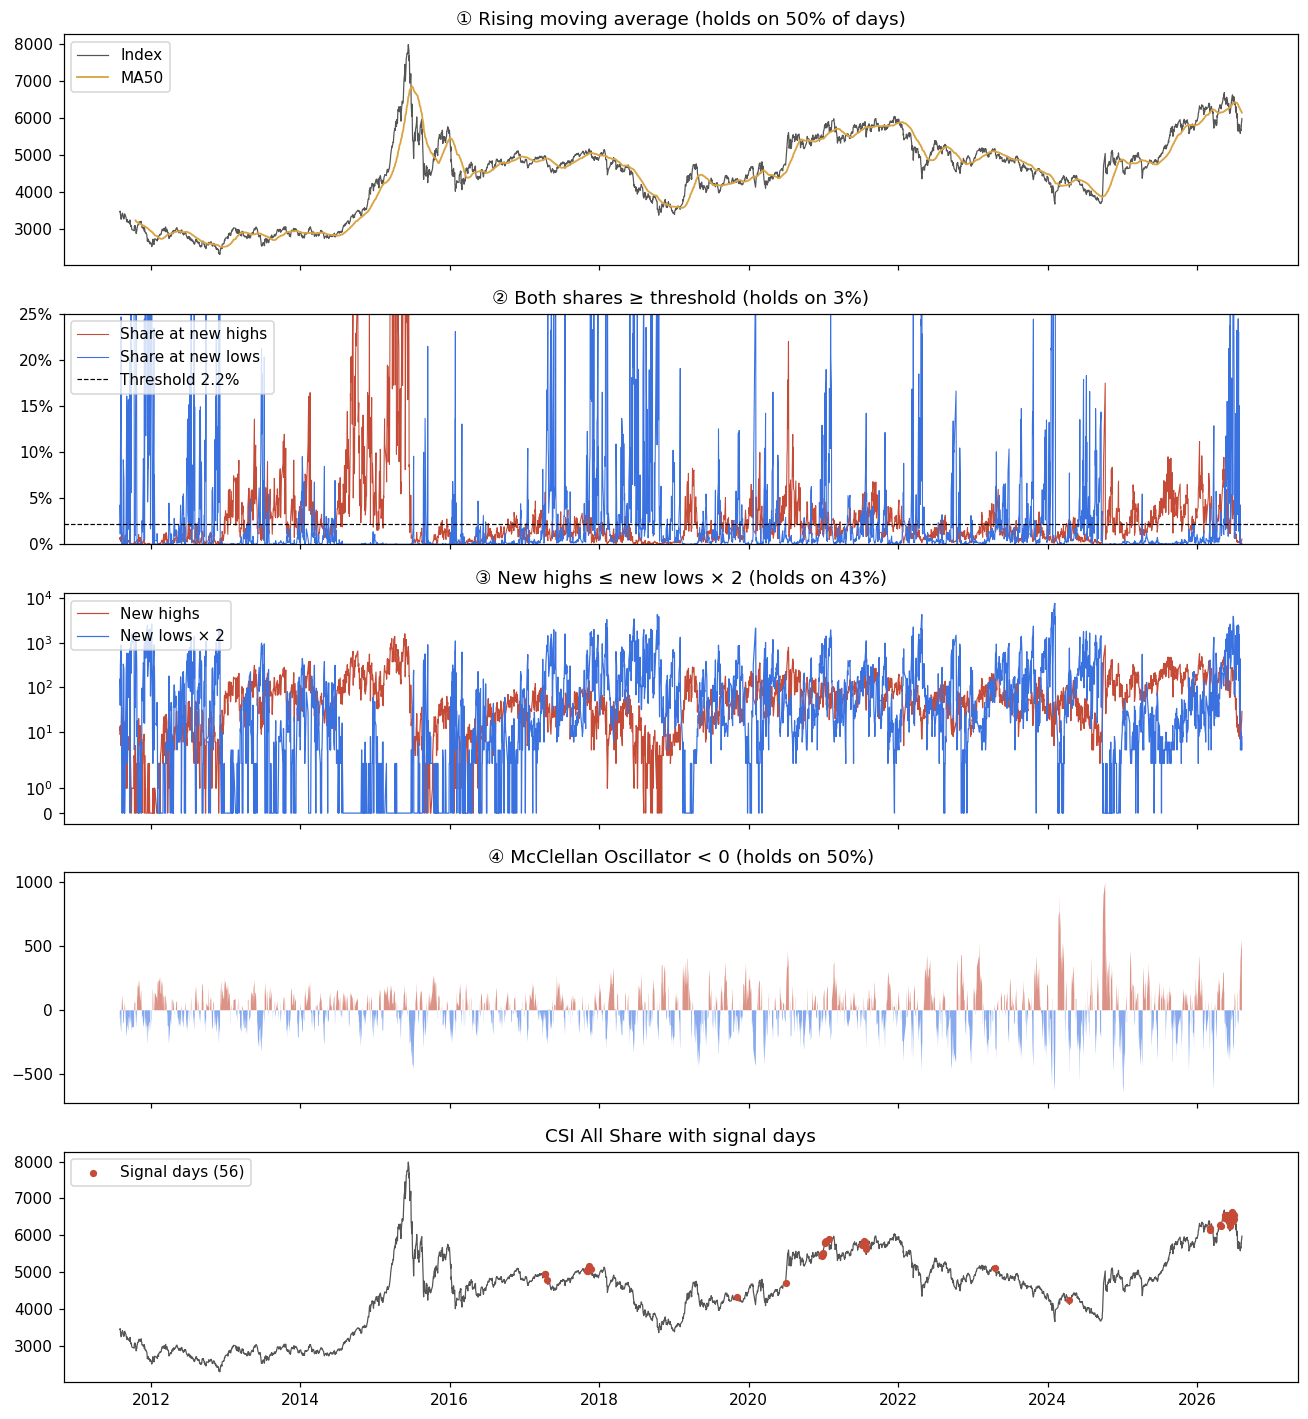

In [3]:
ma = omen.index_full.rolling(p.ma_period).mean().reindex(df.index)

fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
ax = axes[0]
ax.plot(df.index, df.index_close, lw=0.8, color='#555', label='Index')
ax.plot(df.index, ma, lw=1.2, color='#D9A441', label=f'MA{p.ma_period}')
ax.set_title(f'① Rising moving average (holds on {df.cond1.mean():.0%} of days)'); ax.legend(loc='upper left')

ax = axes[1]
ax.plot(df.index, df.high_ratio, lw=0.7, color='#C64B37', label='Share at new highs')
ax.plot(df.index, df.low_ratio, lw=0.7, color='#3971E1', label='Share at new lows')
ax.axhline(p.threshold, color='k', ls='--', lw=0.8, label=f'Threshold {p.threshold:.1%}')
ax.set_ylim(0, 0.25); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_title(f'② Both shares ≥ threshold (holds on {df.cond2.mean():.0%})'); ax.legend(loc='upper left')

ax = axes[2]
ax.plot(df.index, df.new_high, lw=0.8, color='#C64B37', label='New highs')
ax.plot(df.index, df.new_low * p.hl_ratio, lw=0.8, color='#3971E1', label=f'New lows × {p.hl_ratio:g}')
ax.set_yscale('symlog'); ax.set_title(f'③ New highs ≤ new lows × {p.hl_ratio:g} (holds on {df.cond3.mean():.0%})'); ax.legend(loc='upper left')

ax = axes[3]
ax.fill_between(df.index, df.mcclellan, 0, where=df.mcclellan < 0, color='#3971E1', alpha=0.6, lw=0)
ax.fill_between(df.index, df.mcclellan, 0, where=df.mcclellan >= 0, color='#C64B37', alpha=0.6, lw=0)
ax.set_title(f'④ McClellan Oscillator < 0 (holds on {df.cond4.mean():.0%})')

ax = axes[4]
ax.plot(df.index, df.index_close, lw=0.8, color='#555')
sig = df[df.signal]
ax.scatter(sig.index, sig.index_close, s=14, color='#C64B37', zorder=3, label=f'Signal days ({len(sig)})')
ax.set_title(f'{name} with signal days'); ax.legend(loc='upper left')
fig.tight_layout()

## 4. Clusters and subsequent drawdowns

- **cluster**: two or more signals within the window; **single**: only one signal, excluded from the statistics.
- `dd_21d / dd_63d / dd_252d`: **peak-to-trough maximum drawdown** over the next 1 month / 1 quarter / 1 year,
  measured from the confirmation date.
- Grades use the 252-day drawdown: ≤ −20% major drawdown, ≤ −10% moderate pullback, ≤ −5% minor pullback.
  Clusters with less than a year of data so far are marked "pending".

In [4]:
cl = evaluate(df, build_clusters(df, p), p)
show = cl[['cluster_id', 'type', 'start_date', 'end_date', 'confirm_date', 'signal_count',
           'dd_21d', 'dd_63d', 'dd_252d', 'level']].copy()
show['type'] = show['type'].map(TYPE_EN)
show['level'] = show['level'].map(LEVEL_EN)
for c in ['dd_21d', 'dd_63d', 'dd_252d']:
    show[c] = show[c].map(lambda v: '' if pd.isna(v) else f'{v:.1%}')
for c in ['start_date', 'end_date', 'confirm_date']:
    show[c] = show[c].dt.strftime('%Y-%m-%d').fillna('')
show

,cluster_id,type,start_date,end_date,confirm_date,signal_count,dd_21d,dd_63d,dd_252d,level
0,1,cluster,2017-04-10,2017-04-20,2017-04-12,3,-8.7%,-9.1%,-13.6%,moderate pullback
1,2,cluster,2017-10-30,2017-11-21,2017-10-31,6,-4.8%,-6.1%,-34.8%,major drawdown
2,3,single,2019-11-04,2019-11-04,,1,-3.9%,-12.0%,-14.9%,moderate pullback
3,4,single,2020-06-29,2020-06-29,,1,-7.8%,-7.8%,-11.0%,moderate pullback
4,5,cluster,2020-12-23,2021-01-25,2020-12-24,9,-2.0%,-11.0%,-11.0%,moderate pullback
5,6,cluster,2021-07-08,2021-07-29,2021-07-15,8,-7.1%,-7.1%,-28.0%,major drawdown
6,7,single,2023-04-20,2023-04-20,,1,-5.7%,-6.9%,-28.4%,major drawdown
7,8,single,2024-04-15,2024-04-15,,1,-2.9%,-11.6%,-17.2%,moderate pullback
8,9,cluster,2026-03-03,2026-03-04,2026-03-04,2,-9.3%,-9.3%,,pending
9,10,cluster,2026-04-24,2026-06-18,2026-04-28,17,-5.5%,-16.5%,,pending


## 5. Hit rate vs. base rate (the key result)

The research report only gives hit rates, e.g. "the share of valid clusters followed by a ≥ 10% drawdown
within a year". On its own that number means little; **it has to be compared with the probability for a
randomly chosen day (the base rate)**:

- **Base rate (all days)**: treat every day as a signal day; how often does the same window see an equally large drawdown?
- **Base rate (uptrend days)**: sample only days when condition ① holds, removing the contribution of the trend filter itself.
- **Excess = hit rate − base rate**. An excess near zero means the signal adds no information.

In [5]:
m = summarize(df, cl, p)
rows = []
for w in p.dd_windows:
    h, ba, bu = m['window_hits'].get(w), m['baseline_all'].get(w), m['baseline_uptrend'].get(w)
    if not h:
        continue
    rows.append({'Window (days)': w, 'Clusters': h['n'],
                 'Hit rate ≤-10%': h['rate_mid'], 'Base rate (all)': ba['p_mid'],
                 'Base rate (uptrend)': bu['p_mid'], 'Excess': h['rate_mid'] - ba['p_mid'],
                 'Hit rate ≤-20%': h['rate_big'], 'Base rate ≤-20%': ba['p_big'],
                 'Excess ≤-20%': h['rate_big'] - ba['p_big']})
hit = pd.DataFrame(rows).set_index('Window (days)')
hit.style.format({c: '{:.0%}' for c in hit.columns if c != 'Clusters'})

,Clusters,Hit rate ≤-10%,Base rate (all),Base rate (uptrend),Excess,Hit rate ≤-20%,Base rate ≤-20%,Excess ≤-20%
Window (days),,,,,,,,
5,7,0%,1%,1%,-1%,0%,0%,-0%
21,7,14%,13%,11%,2%,0%,2%,-2%
63,6,33%,43%,38%,-10%,0%,7%,-7%
252,4,100%,96%,97%,4%,50%,38%,12%


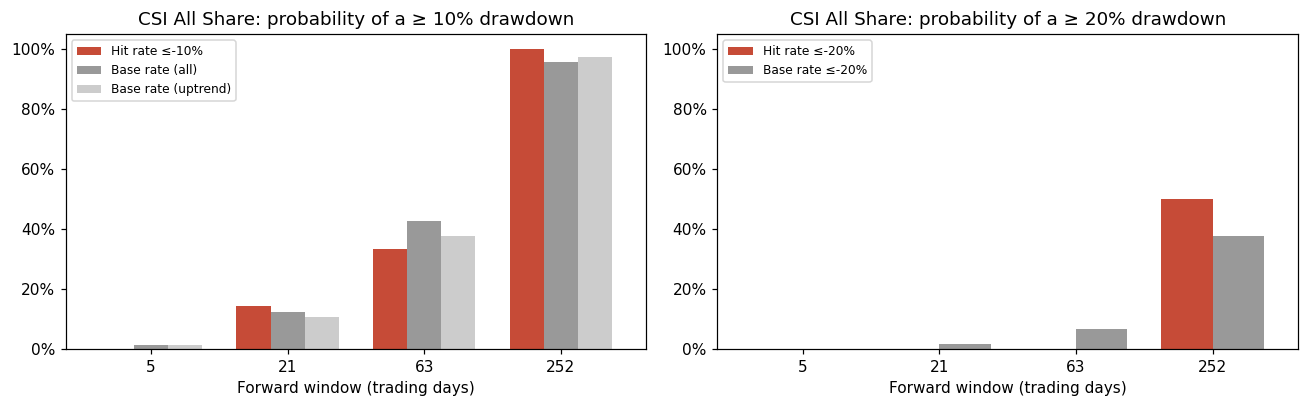

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (lab, cols) in zip(axes, [('≥ 10% drawdown', ['Hit rate ≤-10%', 'Base rate (all)', 'Base rate (uptrend)']),
                                    ('≥ 20% drawdown', ['Hit rate ≤-20%', 'Base rate ≤-20%'])]):
    hit[cols].plot.bar(ax=ax, rot=0, width=0.75, color=['#C64B37', '#999', '#ccc'][:len(cols)])
    ax.set_title(f'{name}: probability of a {lab}'); ax.set_xlabel('Forward window (trading days)')
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()

## 6. Case study: why there was no signal in 2015

June 2015 was a major top for A-shares, yet the indicator never fired. Listing the daily values around the top
shows where it got stuck:

In [7]:
win = df.loc['2015-06-08':'2015-07-10', ['index_close', 'cond1', 'high_ratio', 'low_ratio',
                                         'cond2', 'mcclellan', 'cond4', 'signal']]
print('Days with condition ② holding, Jun–Sep 2015:', int(df.loc['2015-06':'2015-09', 'cond2'].sum()))
win.style.format({'index_close': '{:,.0f}', 'high_ratio': '{:.1%}', 'low_ratio': '{:.1%}',
                  'mcclellan': '{:,.0f}'})

Days with condition ② holding, Jun–Sep 2015: 0


,index_close,cond1,high_ratio,low_ratio,cond2,mcclellan,cond4,signal
2015-06-08 00:00:00,"7,756",True,21.7%,0.0%,False,-26,True,False
2015-06-09 00:00:00,"7,732",True,15.7%,0.0%,False,-53,True,False
2015-06-10 00:00:00,"7,814",True,20.4%,0.0%,False,-13,True,False
2015-06-11 00:00:00,"7,892",True,33.4%,0.0%,False,5,False,False
2015-06-12 00:00:00,"7,984",True,38.9%,0.0%,False,20,False,False
2015-06-15 00:00:00,"7,830",True,22.2%,0.0%,False,-44,True,False
2015-06-16 00:00:00,"7,550",True,8.4%,0.0%,False,-135,True,False
2015-06-17 00:00:00,"7,687",True,8.6%,0.0%,False,-83,True,False
2015-06-18 00:00:00,"7,412",True,6.0%,0.0%,False,-167,True,False
2015-06-19 00:00:00,"6,943",True,1.3%,0.0%,False,-263,True,False


Condition ② needs the shares of new highs and new lows to be ≥ 2.2% **on the same day**, but in 2015 the market
went from broad rally to broad sell-off with almost no transition:

- Mid-June top: 30%–40% of stocks at new highs, almost none at new lows.
- Late-June sell-off: the share at new highs quickly fell below 1%, while new lows were still near zero.
- July 7–8: new lows finally jumped to 5%–10%, but new highs were below 0.5% by then, and condition ① had already
  failed on July 3 (the moving average turned down).

So the "split market" phase, with many new highs and many new lows at once, never happened, and condition ② did
not hold on a single day. This is a blind spot of the indicator (markets that rise and fall in unison, flash
crashes), not a calculation error.

## 7. Summary across five indices

For each index, condition ① and the drawdowns use the index itself, while conditions ②③④ use the matching
universe: CSI All Share (whole market), SSE Composite (Shanghai-listed only), CSI 300 / CSI 500 / CSI 1000
(index constituents).

In [8]:
with quiet():
    store, cache = _make_store(), BreadthCache()
rows = []
for key, st in STRATEGIES.items():
    pn = Panel(state_rule=st.state_rule, exclude_boards=st.params.exclude_boards,
               include_exchanges=st.params.include_exchanges)
    o = Omen(st, pn, store, cache)
    with quiet():
        d = o.compute(st.start or config.START, pn.last_date.strftime('%Y-%m-%d'))
    c = evaluate(d, build_clusters(d, st.params), st.params)
    mm = summarize(d, c, st.params)
    ba = mm['baseline_all'][st.params.grade_window]
    rows.append({'Index': INDEX_EN[st.name], 'Start': f'{d.index[0]:%Y-%m}', 'Signal days': mm['signal_days'],
                 'Valid clusters': mm['n_clusters_valid'], 'Gradable': mm['n_gradable'],
                 'Hit rate ≤-10%': mm['hit_rate'], 'Base rate ≤-10%': ba['p_mid'],
                 'Hit rate ≤-20%': mm['hit_rate_big'], 'Base rate ≤-20%': ba['p_big']})
summary = pd.DataFrame(rows).set_index('Index')
summary['Excess ≤-10%'] = summary['Hit rate ≤-10%'] - summary['Base rate ≤-10%']
summary['Excess ≤-20%'] = summary['Hit rate ≤-20%'] - summary['Base rate ≤-20%']
summary.style.format({c: '{:.0%}' for c in summary.columns if 'rate' in c or 'Excess' in c})

,Start,Signal days,Valid clusters,Gradable,Hit rate ≤-10%,Base rate ≤-10%,Hit rate ≤-20%,Base rate ≤-20%,Excess ≤-10%,Excess ≤-20%
Index,,,,,,,,,,
CSI All Share,2011-08,56,7,4,100%,96%,50%,38%,4%,12%
SSE Composite,2005-01,82,13,10,80%,85%,50%,44%,-5%,6%
CSI 300,2005-04,134,19,14,100%,91%,50%,54%,9%,-4%
CSI 500,2007-01,85,12,9,89%,96%,56%,59%,-7%,-3%
CSI 1000,2014-10,53,7,4,100%,100%,100%,64%,0%,36%


## 8. Conclusions and limitations

**Conclusion: on A-shares, the Hindenburg Omen shows no consistent predictive power.**

- **High hit rates, but equally high base rates.** Over a 252-day window the base rate of a ≥ 10% drawdown is
  85%–100%: A-shares almost always see a drawdown that large within a year. Across indices, hit rate minus base rate
  ranges from −7 to +9 percentage points, sometimes positive, sometimes negative.
- **The stricter ≥ 20% threshold is inconsistent in sign.** Excess ranges from −4 to +36 percentage points; the
  largest, +36, comes from CSI 1000 with only 4 gradable clusters and is very likely noise.
- **No short-term edge.** For the CSI All Share, the probability of a drawdown within 1 month or 1 quarter after a
  signal is no higher than for a random day.
- **It missed the biggest top.** In a market that rises and falls in unison, as in 2015, condition ② cannot hold.
- Headline figures like "90%+ hit rate" in the research report mainly reflect how often A-shares draw down at all,
  not the signal's predictive power.

**Limitations**

- Each index has only 4 to 14 gradable valid clusters, so hit-rate confidence intervals are wide; the results
  should not be extrapolated.
- The 2.2% threshold was designed for a market of several thousand stocks. CSI 300 has only 300 constituents, so its
  shares jump around a lot; results for the size indices are best compared only with their own history.
- Parameters can be tuned in the parameter lab, but with samples this small, a combination that looks "very
  accurate" is most likely overfitted.

For research only; not investment advice.